# Modelo Random Forest — AirPrice

Implementa y evalúa el modelo **Random Forest** (ensemble de Bagging) para la clasificación del rango de precio de alojamientos Airbnb en Londres.

Usa el preprocesamiento compartido dentro de un `Pipeline`, la **misma semilla** y la **misma división estratificada** que los demás modelos del proyecto.

In [6]:
import sys
sys.path.append("../..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

from src.utils import (
    CLASES,
    REPORTS_DIR,
    SEED,
    cargar_dataset,
    evaluar_modelo,
    fijar_semilla,
    guardar_modelo,
    split_estratificado,
)
from src.preprocessing import descartar_columnas
from src.model_random_forest import construir_modelo_random_forest

sns.set_theme(style="whitegrid")
fijar_semilla(SEED)
print("Semilla utilizada:", SEED)

Semilla utilizada: 42


## 1. Carga y división de datos

Se usa `airprice_clean.csv` (igual que los demás modelos para que los resultados sean comparables) con la división estratificada compartida.

In [7]:
df = descartar_columnas(cargar_dataset())
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

X_train, X_val, X_test, y_train, y_val, y_test = split_estratificado(
    df,
    target="price_range",
    excluir=["price_clean", "id"],
    seed=SEED,
)

print("Train:", X_train.shape)
print("Validación:", X_val.shape)
print("Test:", X_test.shape)

Filas: 61617
Columnas: 25
Train: (43131, 22)
Validación: (9243, 22)
Test: (9243, 22)


## 2. Modelo base

Random Forest con configuración por defecto (`n_estimators=300`), evaluado en validación.

In [8]:
modelo_base = construir_modelo_random_forest(X_train, n_estimators=300)
modelo_base.fit(X_train, y_train)

metricas_base = evaluar_modelo(
    y_val,
    modelo_base.predict(X_val),
    etiquetas=CLASES,
)

print({k: round(v, 4) for k, v in metricas_base.items() if k != "matriz_confusion"})

{'accuracy': 0.6844, 'balanced_accuracy': 0.684, 'f1_macro': 0.6818, 'f1_weighted': 0.6821}


## 3. Ajuste de hiperparámetros (grid manual)

Se evalúa un grid pequeño de `n_estimators`, `max_depth` y `max_features` sobre el conjunto de **validación**, seleccionando por F1-Macro.

In [9]:
GRID = [
    {"n_estimators": n, "max_depth": d, "max_features": f}
    for n in [100, 300]
    for d in [None, 20, 40]
    for f in ["sqrt", "log2"]
]

resultados = []
for params in GRID:
    modelo = construir_modelo_random_forest(X_train, **params)
    modelo.fit(X_train, y_train)
    met = evaluar_modelo(y_val, modelo.predict(X_val), etiquetas=CLASES)
    resultados.append(
        {
            **params,
            "accuracy": met["accuracy"],
            "balanced_accuracy": met["balanced_accuracy"],
            "f1_macro": met["f1_macro"],
            "f1_weighted": met["f1_weighted"],
        }
    )

resultados_df = pd.DataFrame(resultados).sort_values("f1_macro", ascending=False)
resultados_df

,n_estimators,max_depth,max_features,accuracy,balanced_accuracy,f1_macro,f1_weighted
0,100,NaN,sqrt,0.684951,0.684557,0.682191,0.682505
6,300,NaN,sqrt,0.684410,0.684017,0.681810,0.682126
7,300,NaN,log2,0.684193,0.683798,0.681509,0.681824
11,300,40.0,log2,0.683869,0.683472,0.681172,0.681490
4,100,40.0,sqrt,0.682462,0.682067,0.679971,0.680291
10,300,40.0,sqrt,0.682138,0.681742,0.679517,0.679835
1,100,NaN,log2,0.681056,0.680659,0.678295,0.678612
8,300,20.0,sqrt,0.679217,0.678801,0.675949,0.676270
5,100,40.0,log2,0.676512,0.676109,0.674006,0.674334
3,100,20.0,log2,0.676945,0.676522,0.672981,0.673295


In [10]:
mejor = resultados_df.iloc[0]

mejor_params = {
    "n_estimators": int(mejor["n_estimators"]),
    "max_depth": None if pd.isna(mejor["max_depth"]) else int(mejor["max_depth"]),
    "max_features": mejor["max_features"],
}

print("Mejores hiperparámetros:", mejor_params)
print("F1-Macro (validación):", round(mejor["f1_macro"], 4))

resultados_df.to_csv(REPORTS_DIR / "random_forest_grid.csv", index=False)

Mejores hiperparámetros: {'n_estimators': 100, 'max_depth': None, 'max_features': 'sqrt'}
F1-Macro (validación): 0.6822


## 4. Importancia de variables

Se entrena el mejor modelo y se extrae la importancia de variables (`feature_importances_`) para responder qué características predicen mejor el rango de precio.

In [11]:
modelo_final = construir_modelo_random_forest(X_train, **mejor_params)
modelo_final.fit(X_train, y_train)

nombres = modelo_final.named_steps["preprocesador"].get_feature_names_out()
importancias = modelo_final.named_steps["modelo"].feature_importances_

importancia_df = (
    pd.DataFrame({"variable": nombres, "importancia": importancias})
    .sort_values("importancia", ascending=False)
    .reset_index(drop=True)
)

importancia_df.head(20)

,variable,importancia
0,num__longitude,0.093701
1,num__latitude,0.089805
2,num__amenities_count,0.072173
3,num__availability_365,0.071974
4,num__accommodates,0.068128
5,num__reviews_per_month,0.054989
6,num__number_of_reviews,0.049397
7,cat__room_type_Entire home/apt,0.048564
8,cat__room_type_Private room,0.046469
9,num__review_scores_rating,0.046014


C:\Users\user\AppData\Local\Temp\ipykernel_10200\727268273.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top15, x="importancia", y="variable", palette="viridis")


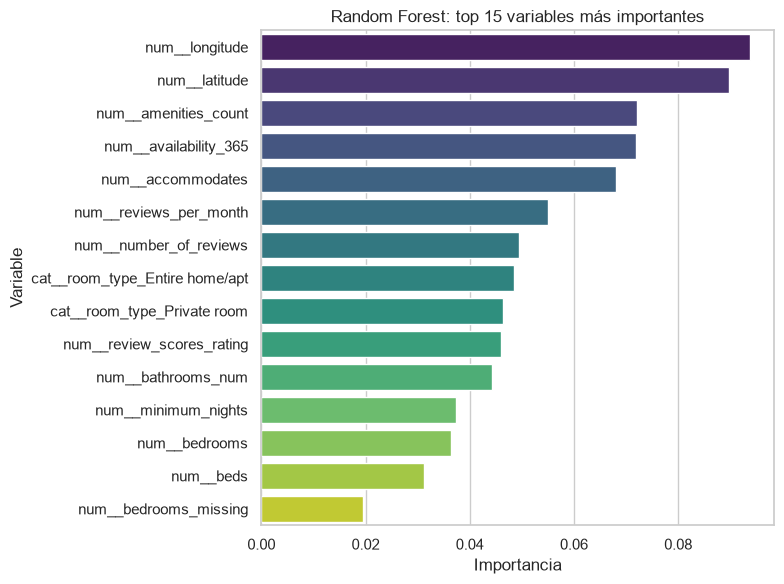

In [12]:
# Gráfico de barras: importancia de variables del Random Forest.
# Se muestran las 15 variables más importantes del modelo final.
# Eje Y: variable (tras el one-hot; el prefijo 'num__'/'cat__' indica su tipo).
# Eje X: importancia (disminución media de impureza de Gini, suma = 1).
# Uso: identificar qué características aportan más a la clasificación del rango de precio.
top15 = importancia_df.head(15)

plt.figure(figsize=(8, 6))
sns.barplot(data=top15, x="importancia", y="variable", palette="viridis")
plt.title("Random Forest: top 15 variables más importantes")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "random_forest_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Evaluación final en test

Métricas del mejor modelo sobre el conjunto de prueba y matriz de confusión.

{'accuracy': 0.6814, 'balanced_accuracy': 0.681, 'f1_macro': 0.6779, 'f1_weighted': 0.6782}


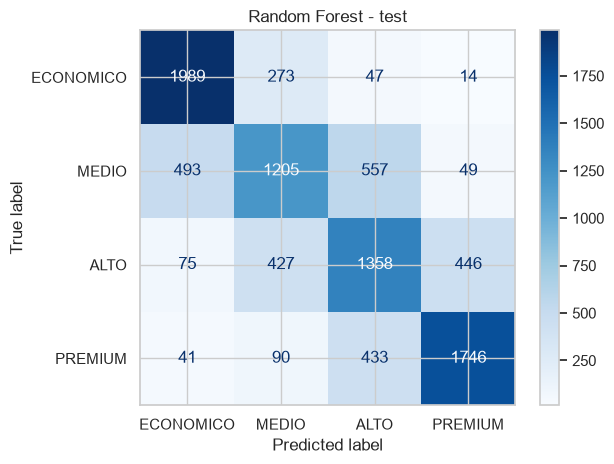

In [ ]:
metricas_test = evaluar_modelo(
    y_test,
    modelo_final.predict(X_test),
    etiquetas=CLASES,
)

print({k: round(v, 4) for k, v in metricas_test.items() if k != "matriz_confusion"})

# Matriz de confusión del modelo final sobre test.
# Eje Y: clase real (price_range). Eje X: predicción de clase.
# La diagonal son aciertos; fuera de la diagonal, confusiones entre rangos.
# Uso: ver si los errores son entre clases vecinas (más leves) o entre extremos.
ConfusionMatrixDisplay(
    metricas_test["matriz_confusion"], display_labels=CLASES
).plot(cmap="Blues")
plt.title("Random Forest - test")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "random_forest_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
metricas_df = pd.DataFrame(
    [
        {
            "modelo": "random_forest",
            **mejor_params,
            **{k: v for k, v in metricas_test.items() if k != "matriz_confusion"},
        }
    ]
)
metricas_df.to_csv(REPORTS_DIR / "random_forest_metricas.csv", index=False)

ruta_modelo = guardar_modelo(modelo_final, "random_forest")
print("Modelo guardado en:", ruta_modelo)
print("Métricas guardadas en:", REPORTS_DIR / "random_forest_metricas.csv")

Modelo guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\models\random_forest.joblib
Métricas guardadas en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\reports\random_forest_metricas.csv


## 6. Conclusión

Modelo Random Forest entrenado con el pipeline común, sin escalado y con la misma división estratificada y semilla que los demás modelos. Se ajustaron `n_estimators`, `max_depth` y `max_features` sobre validación, se reportó la importancia de variables y se evaluó el mejor modelo en el conjunto de prueba. Sus métricas y figuras quedan en `reports/` para la comparación final de los cuatro modelos.